✅ Model Loaded
📦 Detected 11 text regions

🧾 FINAL OCR OUTPUT:

sslatantrrolcssorj ucparmsl uriltuuwtnlwubl 0ulncss 5chooi kanjut kalgau
rtDNim rmancc unlhl ha 9xlnthancbn0atujq ljuj waharaxhurn
ParHhraj Maharaul
rtDNim rmacrmulpnl ruslnt3hnuutaultkqfglnuj waharaxhurn
Saurablr Agarwal
roDNl in rnancc lnmqralnujlltasrvu0aubttk lmlgatl haharahura
ujd
technology.
1j INTR0DUCTI0W
iit


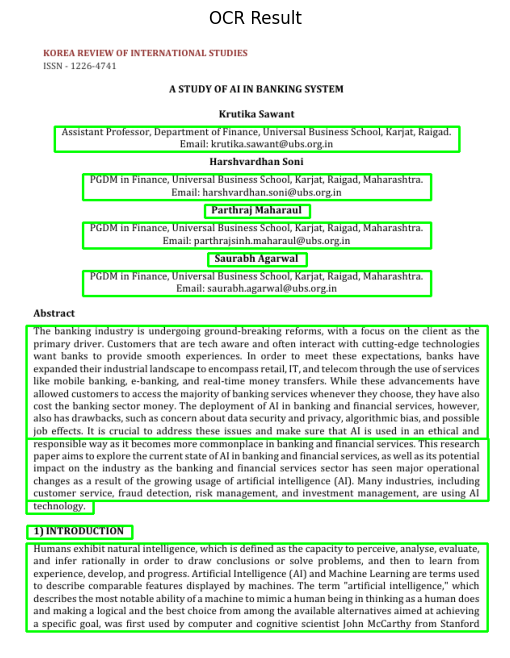

In [3]:
import cv2
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_HEIGHT = 32

# =========================
# CHAR SET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256,bidirectional=True,num_layers=2,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        b,c,h,w = x.size()
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

print("✅ Model Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# DECODER
# =========================
def decode(pred):
    pred = pred.argmax(2).cpu().numpy()[0]

    prev = -1
    text = ""

    for p in pred:
        if p != prev and p != 0:
            text += idx_to_char.get(p, "")
        prev = p

    return text

# =========================
# LOAD IMAGE
# =========================
image = cv2.imread(IMAGE_PATH)

if image is None:
    raise Exception("❌ Image not found! Check path.")

orig = image.copy()
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# =========================
# PREPROCESS
# =========================
thresh = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    15, 8
)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (20,5))
dilated = cv2.dilate(thresh, kernel, iterations=1)

# =========================
# FIND TEXT REGIONS
# =========================
contours, _ = cv2.findContours(
    dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

boxes = []
for cnt in contours:
    x,y,w,h = cv2.boundingRect(cnt)

    # Filter noise
    if w > 50 and h > 15:
        boxes.append((x,y,w,h))

# Sort top-to-bottom
boxes = sorted(boxes, key=lambda b: (b[1], b[0]))

print(f"📦 Detected {len(boxes)} text regions")

# =========================
# OCR
# =========================
final_text = []

for (x,y,w,h) in boxes:
    crop = gray[y:y+h, x:x+w]

    # Resize keeping ratio
    h0, w0 = crop.shape
    new_w = max(int(IMG_HEIGHT * w0 / h0), 1)
    crop = cv2.resize(crop, (new_w, IMG_HEIGHT))

    pil_img = Image.fromarray(crop)
    img_tensor = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds = model(img_tensor)
        text = decode(preds)

    if text.strip():
        final_text.append(text)

    # Draw bounding box
    cv2.rectangle(orig, (x,y), (x+w,y+h), (0,255,0), 2)

# =========================
# OUTPUT TEXT
# =========================
print("\n🧾 FINAL OCR OUTPUT:\n")
for line in final_text:
    print(line)

# =========================
# DISPLAY RESULT (NO ERROR)
# =========================
plt.figure(figsize=(10,8))
plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
plt.title("OCR Result")
plt.axis("off")
plt.show()

✅ Model Loaded
📄 Detected 6 lines

🧾 FINAL OCR OUTPUT:

zvslstant rrolossurj ucpurmcn uruuuuuvuntguhl puslnuss 3chool kaujuk algaut
 PDN n rmsnce lnntljlnullray fhu0tbutj lmlgtl Nlahsraslhura
mmmmwwmmqmuwulmmmuuwmwwl wmu
 rhsumtrsdutdllrautactrwtj usmundtlhtnu nndlivutmdt manvgunuauiat rnclulnl
rd


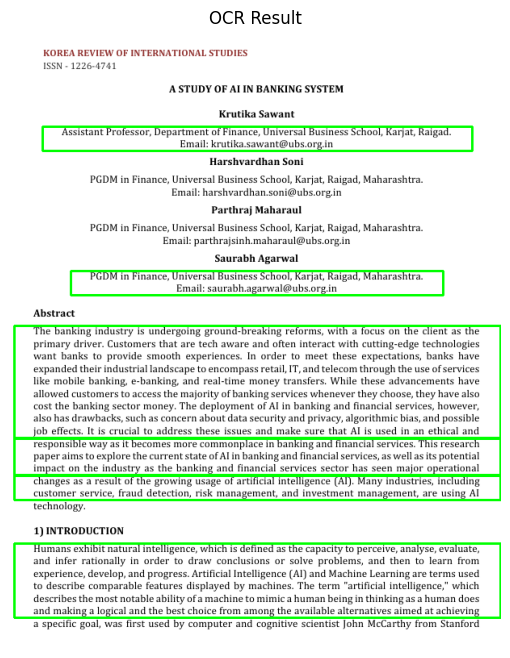

In [4]:
import cv2
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_HEIGHT = 32

# =========================
# CHAR SET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1  # +1 for CTC blank

# =========================
# MODEL (CRNN)
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256,bidirectional=True,num_layers=2,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        b,c,h,w = x.size()
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

print("✅ Model Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# DECODER (CTC GREEDY)
# =========================
def decode(pred):
    pred = pred.argmax(2).cpu().numpy()[0]
    prev = -1
    text = ""

    for p in pred:
        if p != prev and p != 0:
            text += idx_to_char.get(p, "")
        prev = p

    return text

# =========================
# LOAD IMAGE
# =========================
image = cv2.imread(IMAGE_PATH)

if image is None:
    raise Exception("❌ Image not found! Check path.")

orig = image.copy()

# =========================
# PREPROCESS
# =========================
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Noise removal
blur = cv2.GaussianBlur(gray, (5,5), 0)

# Adaptive threshold
thresh = cv2.adaptiveThreshold(
    blur, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    15, 10
)

# =========================
# LINE SEGMENTATION
# =========================
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (50, 3))
dilated = cv2.dilate(thresh, kernel, iterations=1)

contours, _ = cv2.findContours(
    dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

line_boxes = []

for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)

    # Filter valid lines
    if w > 100 and h > 20:
        line_boxes.append((x, y, w, h))

# Sort top to bottom
line_boxes = sorted(line_boxes, key=lambda b: b[1])

print(f"📄 Detected {len(line_boxes)} lines")

# =========================
# OCR PER LINE
# =========================
final_text = []

for (x, y, w, h) in line_boxes:
    line_img = gray[y:y+h, x:x+w]

    # Resize keeping aspect ratio
    h0, w0 = line_img.shape
    new_w = max(int(IMG_HEIGHT * w0 / h0), 1)
    line_img = cv2.resize(line_img, (new_w, IMG_HEIGHT))

    # Convert to tensor
    pil_img = Image.fromarray(line_img)
    img_tensor = transform(pil_img).unsqueeze(0).to(DEVICE)

    # Prediction
    with torch.no_grad():
        preds = model(img_tensor)
        text = decode(preds)

    if text.strip():
        final_text.append(text)

    # Draw bounding box
    cv2.rectangle(orig, (x,y), (x+w,y+h), (0,255,0), 2)

# =========================
# PRINT RESULT
# =========================
print("\n🧾 FINAL OCR OUTPUT:\n")
for line in final_text:
    print(line)

# =========================
# DISPLAY RESULT (JUPYTER SAFE)
# =========================
plt.figure(figsize=(12,8))
plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
plt.title("OCR Result")
plt.axis("off")
plt.show()

C:\Users\manis\ocr_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\manis\ocr_env\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\manis\.cache\huggingface\hub\models--microsoft--trocr-base-printed. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see thi

✅ CRNN + TrOCR Loaded

🧾 FINAL OUTPUT:

ssistancrrolcsr peparmnl uruaustwuniwubj uuincs cnoolk kanau kuguu
PoDNi m Fmncc pnnljalnulltasrwu@uhuy lmlgau hiaharashra
 uamrujnjvtc qrguusnunli rxpcrrnwa nu utr u mcrtr tu cxuuntrpng ganuu nlya
 krnthlt bnunj r hnumglnt rernmnmrnclirnauu cwnu rgu htanusnrig huga
RW0WxuWmW unWum mw
WWuluWum utllulumww lWu
 cuaumsrsarucu lrouudttcdj umonagcmcn undihvctmcn manjsununu arc uslngul
 anuisriuiunlly ln ndtjn trwwionduluns ai suvduqlemu anl tian ld lcarnln
 rdururnbc tqnpnt puutcsuisnlvtt ulmnnc1hslurmcunn a ndlcncruwlirl
 uranbtnga lui uunn nllukt uhnudrnum amnnuthu uulaulcalt nuiusumad uuunu vng


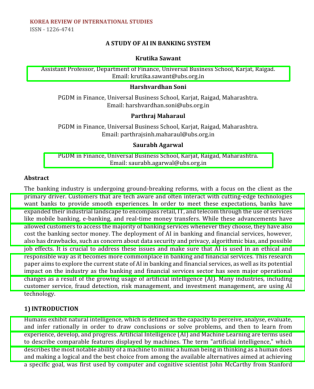

In [5]:
import cv2
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_HEIGHT = 32

# =========================
# CHAR SET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# CRNN MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )
        self.rnn = nn.LSTM(512,256,bidirectional=True,num_layers=2,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        b,c,h,w = x.size()
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# LOAD MODELS
# =========================
crnn = CRNN(NUM_CLASSES).to(DEVICE)
crnn.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
crnn.eval()

processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-printed")
trocr = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-printed").to(DEVICE)

print("✅ CRNN + TrOCR Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# CRNN DECODER
# =========================
def decode(pred):
    pred = pred.argmax(2).cpu().numpy()[0]
    prev = -1
    text = ""

    for p in pred:
        if p != prev and p != 0:
            text += idx_to_char.get(p, "")
        prev = p

    return text

# =========================
# CONFIDENCE CHECK
# =========================
def is_bad_prediction(text):
    if len(text) < 2:
        return True
    if text.count(" ") > len(text) * 0.5:
        return True
    return False

# =========================
# LOAD IMAGE
# =========================
image = cv2.imread(IMAGE_PATH)
orig = image.copy()
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# =========================
# DETECTION (LINES)
# =========================
thresh = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    15, 10
)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (60,4))
dilated = cv2.dilate(thresh, kernel, iterations=1)

contours,_ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

boxes = []
for cnt in contours:
    x,y,w,h = cv2.boundingRect(cnt)
    if w>80 and h>20:
        boxes.append((x,y,w,h))

boxes = sorted(boxes, key=lambda b: b[1])

# =========================
# OCR PIPELINE
# =========================
results = []

for (x,y,w,h) in boxes:
    crop = gray[y:y+h, x:x+w]

    # ---- CRNN ----
    h0,w0 = crop.shape
    new_w = int(IMG_HEIGHT * w0 / h0)
    resized = cv2.resize(crop, (new_w, IMG_HEIGHT))

    pil_img = Image.fromarray(resized)
    tensor = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        pred = crnn(tensor)
        text_crnn = decode(pred)

    # ---- FALLBACK (TrOCR) ----
    if is_bad_prediction(text_crnn):
        pil_color = Image.fromarray(cv2.cvtColor(orig[y:y+h,x:x+w], cv2.COLOR_BGR2RGB))
        pixel_values = processor(images=pil_color, return_tensors="pt").pixel_values.to(DEVICE)

        with torch.no_grad():
            ids = trocr.generate(pixel_values)

        text = processor.batch_decode(ids, skip_special_tokens=True)[0]
    else:
        text = text_crnn

    results.append(text)

    cv2.rectangle(orig, (x,y), (x+w,y+h), (0,255,0), 2)

# =========================
# OUTPUT
# =========================
print("\n🧾 FINAL OUTPUT:\n")
for r in results:
    print(r)

# =========================
# DISPLAY
# =========================
plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

✅ Model Loaded
📄 Detected 5 TEXT LINES

🧾 FINAL OCR OUTPUT:

 suztrztor nrrmmhroukt grunug
zeaaea waWW gv aeqcogz
ccrqg
m c
fja@sww


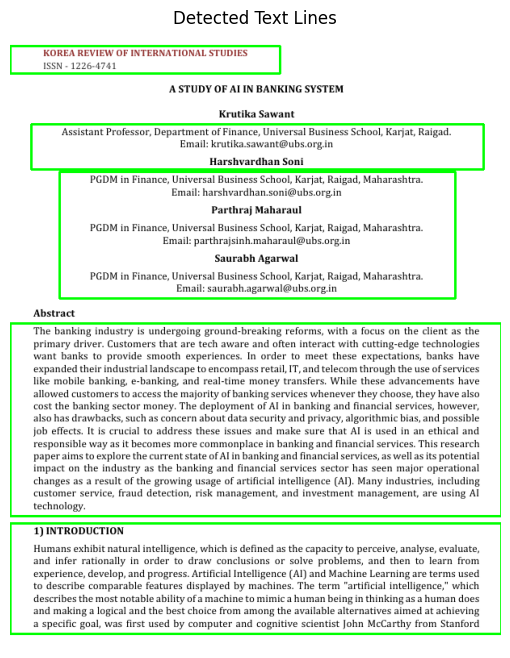

In [6]:
import cv2
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_HEIGHT = 32

# =========================
# CHAR SET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# CRNN MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256,bidirectional=True,num_layers=2,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        b,c,h,w = x.size()
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

print("✅ Model Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# DECODER
# =========================
def decode(pred):
    pred = pred.argmax(2).cpu().numpy()[0]
    prev = -1
    text = ""

    for p in pred:
        if p != prev and p != 0:
            text += idx_to_char.get(p, "")
        prev = p

    return text

# =========================
# CRAFT-LIKE DETECTOR
# =========================
def detect_text_lines(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Edge detection (text strokes)
    edges = cv2.Canny(gray, 50, 150)

    # Dilate horizontally (connect words → lines)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (40, 5))
    dilated = cv2.dilate(edges, kernel, iterations=2)

    # Close gaps
    kernel2 = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
    closed = cv2.morphologyEx(dilated, cv2.MORPH_CLOSE, kernel2)

    # Find contours (LINES, not words)
    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    lines = []
    for cnt in contours:
        x,y,w,h = cv2.boundingRect(cnt)

        # Filter noise
        if w > 100 and h > 20:
            lines.append((x,y,w,h))

    # Sort TOP → BOTTOM
    lines = sorted(lines, key=lambda b: b[1])

    return lines

# =========================
# LOAD IMAGE
# =========================
image = cv2.imread(IMAGE_PATH)

if image is None:
    raise Exception("❌ Image not found!")

orig = image.copy()

# =========================
# DETECT LINES (FIXED PART)
# =========================
lines = detect_text_lines(image)

print(f"📄 Detected {len(lines)} TEXT LINES")

# =========================
# OCR LINE BY LINE
# =========================
final_text = []

for (x,y,w,h) in lines:

    line_img = image[y:y+h, x:x+w]
    gray = cv2.cvtColor(line_img, cv2.COLOR_BGR2GRAY)

    # Improve contrast
    gray = cv2.equalizeHist(gray)

    # Resize keeping ratio
    h0, w0 = gray.shape
    new_w = max(int(IMG_HEIGHT * w0 / h0), 1)
    resized = cv2.resize(gray, (new_w, IMG_HEIGHT))

    pil_img = Image.fromarray(resized)
    img_tensor = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds = model(img_tensor)
        text = decode(preds)

    final_text.append(text)

    # Draw box
    cv2.rectangle(orig, (x,y), (x+w,y+h), (0,255,0), 2)

# =========================
# OUTPUT
# =========================
print("\n🧾 FINAL OCR OUTPUT:\n")
for line in final_text:
    print(line)

# =========================
# DISPLAY
# =========================
plt.figure(figsize=(12,8))
plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
plt.title("Detected Text Lines")
plt.axis("off")
plt.show()

✅ Model Loaded
📄 Detected 5 TEXT LINES

🧾 FINAL OCR OUTPUT:

 suztrztor nrrmmhroukt grunug
zeaaea waWW gv aeqcogz
ccrqg
m c
fja@sww


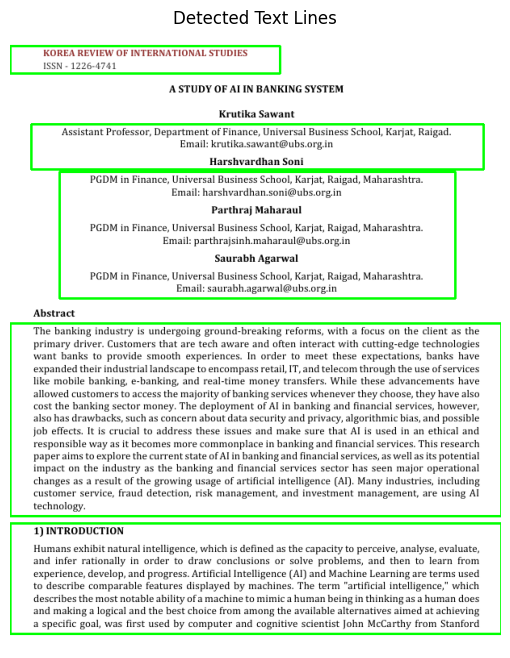

In [7]:
import cv2
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# =========================
# CONFIG
# =========================
MODEL_PATH = "crnn_model_final.pth"
IMAGE_PATH = "anip.png"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_HEIGHT = 32

# =========================
# CHAR SET
# =========================
CHARS = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789@._- "
idx_to_char = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1

# =========================
# CRNN MODEL
# =========================
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1,64,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,1,1), nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(128,256,3,1,1), nn.ReLU(),
            nn.Conv2d(256,256,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(256,512,3,1,1), nn.ReLU(), nn.BatchNorm2d(512),
            nn.Conv2d(512,512,3,1,1), nn.ReLU(), nn.MaxPool2d((2,1)),
            nn.Conv2d(512,512,2,1,0), nn.ReLU()
        )

        self.rnn = nn.LSTM(512,256,bidirectional=True,num_layers=2,batch_first=True)
        self.fc = nn.Linear(512,num_classes)

    def forward(self,x):
        x = self.cnn(x)
        b,c,h,w = x.size()
        x = x.squeeze(2).permute(0,2,1)
        x,_ = self.rnn(x)
        x = self.fc(x)
        return x.log_softmax(2)

# =========================
# LOAD MODEL
# =========================
model = CRNN(NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

print("✅ Model Loaded")

# =========================
# TRANSFORM
# =========================
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# =========================
# DECODER
# =========================
def decode(pred):
    pred = pred.argmax(2).cpu().numpy()[0]
    prev = -1
    text = ""

    for p in pred:
        if p != prev and p != 0:
            text += idx_to_char.get(p, "")
        prev = p

    return text

# =========================
# CRAFT-LIKE DETECTOR
# =========================
def detect_text_lines(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Edge detection (text strokes)
    edges = cv2.Canny(gray, 50, 150)

    # Dilate horizontally (connect words → lines)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (40, 5))
    dilated = cv2.dilate(edges, kernel, iterations=2)

    # Close gaps
    kernel2 = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
    closed = cv2.morphologyEx(dilated, cv2.MORPH_CLOSE, kernel2)

    # Find contours (LINES, not words)
    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    lines = []
    for cnt in contours:
        x,y,w,h = cv2.boundingRect(cnt)

        # Filter noise
        if w > 100 and h > 20:
            lines.append((x,y,w,h))

    # Sort TOP → BOTTOM
    lines = sorted(lines, key=lambda b: b[1])

    return lines

# =========================
# LOAD IMAGE
# =========================
image = cv2.imread(IMAGE_PATH)

if image is None:
    raise Exception("❌ Image not found!")

orig = image.copy()

# =========================
# DETECT LINES (FIXED PART)
# =========================
lines = detect_text_lines(image)

print(f"📄 Detected {len(lines)} TEXT LINES")

# =========================
# OCR LINE BY LINE
# =========================
final_text = []

for (x,y,w,h) in lines:

    line_img = image[y:y+h, x:x+w]
    gray = cv2.cvtColor(line_img, cv2.COLOR_BGR2GRAY)

    # Improve contrast
    gray = cv2.equalizeHist(gray)

    # Resize keeping ratio
    h0, w0 = gray.shape
    new_w = max(int(IMG_HEIGHT * w0 / h0), 1)
    resized = cv2.resize(gray, (new_w, IMG_HEIGHT))

    pil_img = Image.fromarray(resized)
    img_tensor = transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds = model(img_tensor)
        text = decode(preds)

    final_text.append(text)

    # Draw box
    cv2.rectangle(orig, (x,y), (x+w,y+h), (0,255,0), 2)

# =========================
# OUTPUT
# =========================
print("\n🧾 FINAL OCR OUTPUT:\n")
for line in final_text:
    print(line)

# =========================
# DISPLAY
# =========================
plt.figure(figsize=(12,8))
plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
plt.title("Detected Text Lines")
plt.axis("off")
plt.show()